<a href="https://colab.research.google.com/github/enzopuc2007/RAM_Memory_Management/blob/main/src/Data_Work_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/enzopuc2007/RAM_Memory_Management/blob/main/src/Data_Work_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto 2 — Sprint 1 — Planilha 2 (depois da intervenção)

Análise do uso da capacidade de memória RAM (%) em 100 servidores após a troca dos módulos: representação gráfica, média e desvio-padrão, contagem de observações no intervalo de referência e comparação com os dados anteriores à intervenção (Questões 7.2 a 8).

### Leitura dos dados

As planilhas devem estar na mesma pasta do notebook. Na Planilha 2 a coluna chama-se `Memória RAM (%)`.

In [ ]:
# Importação das bibliotecas que são usadas
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
import pylab

In [ ]:
arquivo = 'Planilha 2 - Memória RAM.xlsx'
coluna = 'Memória RAM (%)'

df = pd.read_excel(arquivo)
print(f"Observações lidas: {len(df)}")
print(f"Colunas: {list(df.columns)}")
df.head()

Observações lidas: 100
Colunas: ['Memória RAM (%)']


,Memória RAM (%)
0,77.256938
1,61.218445
2,67.534175
3,60.998263
4,53.326666


### Questão 7.2 — Representação gráfica

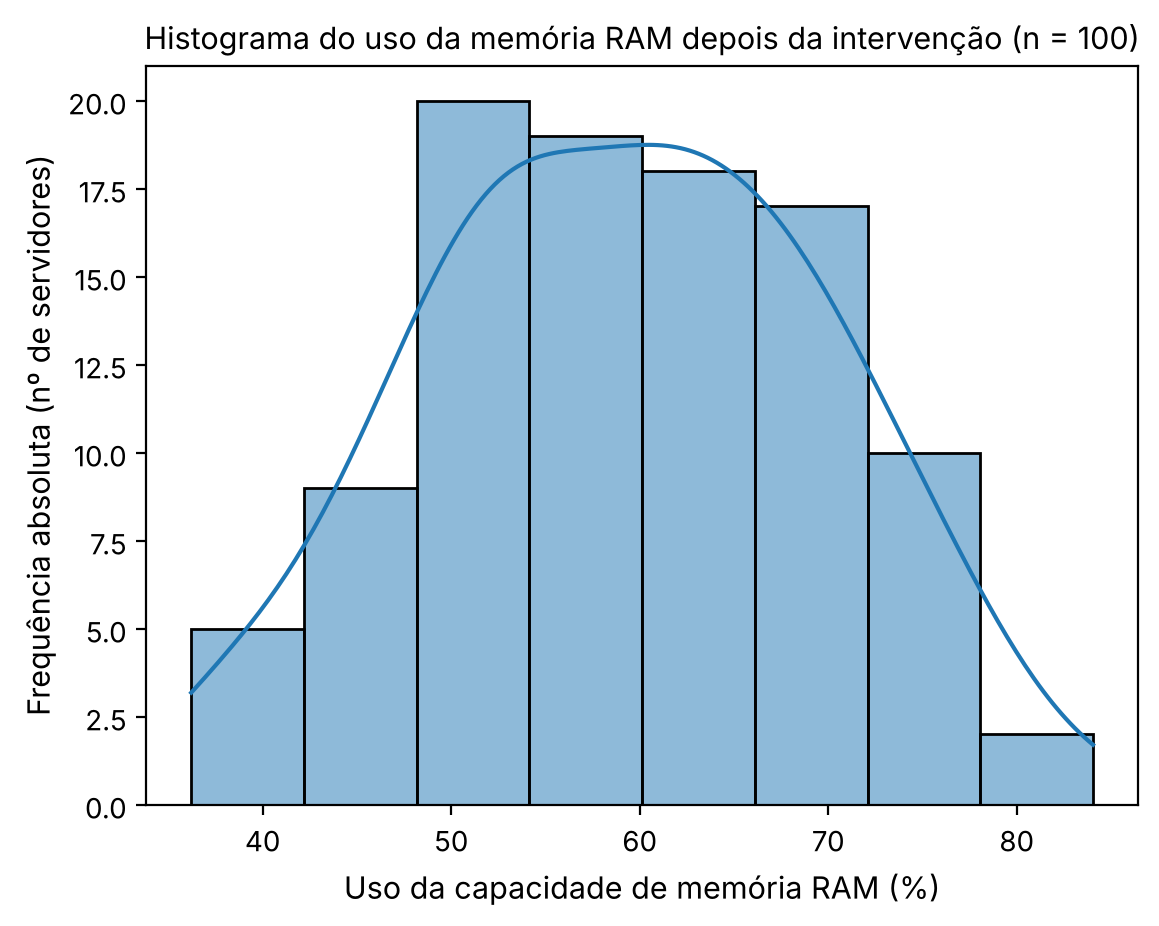

In [ ]:
sns.histplot(data=df[coluna], kde=True)
plt.title('Histograma do uso da memória RAM depois da intervenção (n = 100)', fontsize=11)
plt.xlabel('Uso da capacidade de memória RAM (%)', fontsize=11)
plt.ylabel('Frequência absoluta (nº de servidores)', fontsize=11)
plt.show()

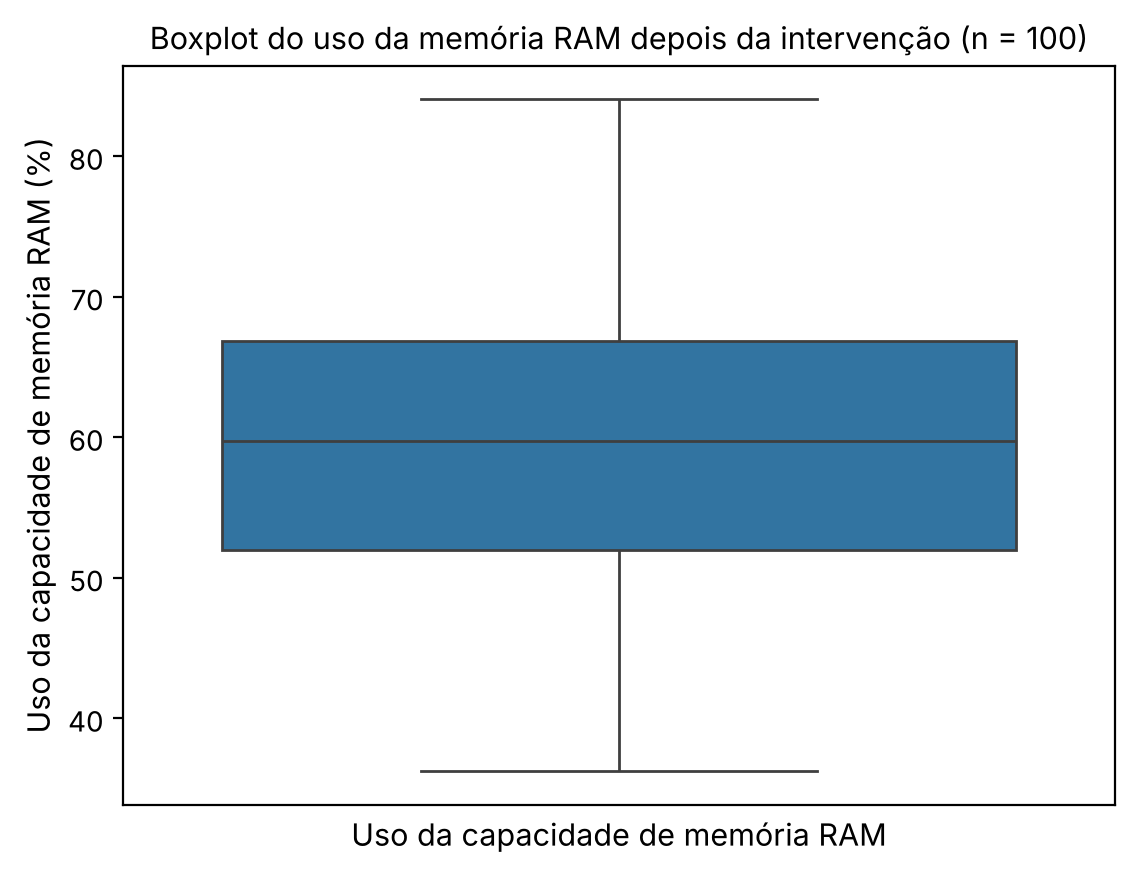

In [ ]:
sns.boxplot(data=df[coluna])
plt.title('Boxplot do uso da memória RAM depois da intervenção (n = 100)', fontsize=11)
plt.ylabel('Uso da capacidade de memória RAM (%)', fontsize=11)
plt.xlabel('Uso da capacidade de memória RAM', fontsize=11)
plt.xticks([])
plt.show()

### Questão 7.3 — Média e desvio-padrão

In [ ]:
media = df[coluna].mean()
dpad = df[coluna].std(ddof=1)

print(f"Média .........: {media:.2f} %")
print(f"Desvio-padrão .: {dpad:.2f} pontos percentuais")
print(f"Mediana .......: {df[coluna].median():.2f} %")

Média .........: 59.21 %
Desvio-padrão .: 10.58 pontos percentuais
Mediana .......: 59.70 %


### Questão 7.4 — Quantidade de observações no intervalo de referência

O intervalo escolhido é a faixa de uso considerada adequada, de 40% a 60% da capacidade, a mesma analisada na Questão 5, porque o objetivo da intervenção é aumentar a quantidade de servidores que operam dentro dela.

In [ ]:
a = 40
b = 60

dentro = ((df[coluna] >= a) & (df[coluna] <= b)).sum()
print(f"Servidores com uso entre {a} % e {b} %: {dentro} de {len(df)} "
      f"= {dentro / len(df) * 100:.2f} %")

Servidores com uso entre 40 % e 60 %: 47 de 100 = 47.00 %


### Questão 8 — Comparação entre os dois cenários

Critério 1: proporção de servidores dentro da faixa adequada de 40% a 60%.

Critério 2: proporção de servidores acima do limite crítico de 70%.

In [ ]:
df_antes = pd.read_excel('Planilha 1 - Memória RAM.xlsx')
antes = df_antes['Memória_RAM_pct']
depois = df[coluna]

resumo = pd.DataFrame({
    'Antes (n = %d)' % len(antes): [
        round(antes.mean(), 2),
        round(antes.std(ddof=1), 2),
        round(antes.median(), 2),
        f"{((antes >= 40) & (antes <= 60)).sum()} ({((antes >= 40) & (antes <= 60)).mean() * 100:.2f} %)",
        f"{(antes > 70).sum()} ({(antes > 70).mean() * 100:.2f} %)"],
    'Depois (n = %d)' % len(depois): [
        round(depois.mean(), 2),
        round(depois.std(ddof=1), 2),
        round(depois.median(), 2),
        f"{((depois >= 40) & (depois <= 60)).sum()} ({((depois >= 40) & (depois <= 60)).mean() * 100:.2f} %)",
        f"{(depois > 70).sum()} ({(depois > 70).mean() * 100:.2f} %)"]
}, index=['Média (%)', 'Desvio-padrão (p.p.)', 'Mediana (%)',
          'Servidores entre 40% e 60%', 'Servidores acima de 70%'])

resumo

,Antes (n = 300),Depois (n = 100)
Média (%),47.13,59.21
Desvio-padrão (p.p.),10.52,10.58
Mediana (%),46.74,59.7
Servidores entre 40% e 60%,192 (64.00 %),47 (47.00 %)
Servidores acima de 70%,6 (2.00 %),16 (16.00 %)


In [ ]:
criterio_1 = ((depois >= 40) & (depois <= 60)).mean() * 100 - ((antes >= 40) & (antes <= 60)).mean() * 100
criterio_2 = (depois > 70).mean() * 100 - (antes > 70).mean() * 100

print(f"Critério 1 — servidores na faixa de 40% a 60%: {criterio_1:+.2f} pontos percentuais")
print(f"Critério 2 — servidores acima de 70%: {criterio_2:+.2f} pontos percentuais")

Critério 1 — servidores na faixa de 40% a 60%: -17.00 pontos percentuais
Critério 2 — servidores acima de 70%: +14.00 pontos percentuais
